# In-Class Practice: Decision Trees
6710503739 Kawinphop

## 1. Prepare

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import StratifiedKFold, cross_val_score

df = pd.read_csv('Social_Network_Ads_2.csv')
print(df.dtypes, '\n\nMissing values:\n', df.isna().sum(), sep='')
print('\nLabel counts:\n', df['Purchased'].value_counts(), sep='')

User ID            int64
Gender               str
Age                int64
EstimatedSalary    int64
Purchased          int64
dtype: object

Missing values:
User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

Label counts:
Purchased
0    257
1    143
Name: count, dtype: int64


In [2]:
y = df['Purchased']                                   # label
X = df.drop(columns=['User ID', 'Purchased'])         # User ID excluded
X['Gender'] = (X['Gender'] == 'Male').astype(int)     # Male=1, Female=0
X.head()

,Gender,Age,EstimatedSalary
0,1,19,19000
1,1,35,20000
2,0,26,43000
3,0,27,57000
4,1,19,76000


## 2. Baseline (10-fold stratified CV, shuffle, seed=42)

In [3]:
SEED = 42
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)   # same folds used everywhere
base = dict(criterion='gini', max_depth=4, min_samples_leaf=5, random_state=SEED)
s = cross_val_score(DecisionTreeClassifier(**base), X, y, cv=cv, scoring='accuracy')
print('Folds: 10 | seed:', SEED, '| params:', base)
print(f'CV accuracy = {s.mean():.4f} +/- {s.std():.4f}')

Folds: 10 | seed: 42 | params: {'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 5, 'random_state': 42}
CV accuracy = 0.8775 +/- 0.0564


## 3. Criteria comparison

In [4]:
crit = []
for c in ['gini', 'entropy']:   # entropy = Information Gain
    s = cross_val_score(DecisionTreeClassifier(**{**base, 'criterion': c}), X, y, cv=cv)
    crit.append({'criterion': c, 'mean_acc': round(s.mean(), 4), 'std': round(s.std(), 4)})
pd.DataFrame(crit)

,criterion,mean_acc,std
0,gini,0.8775,0.0564
1,entropy,0.8825,0.0613


## 4. Tuning: max_depth 2–8 × min_samples_leaf 1–10 (criterion = entropy, same folds)

In [5]:
rows = []
for d in range(2, 9):
    for l in range(1, 11):
        s = cross_val_score(DecisionTreeClassifier(criterion='entropy', max_depth=d,
                            min_samples_leaf=l, random_state=SEED), X, y, cv=cv)
        rows.append({'max_depth': d, 'min_samples_leaf': l,
                     'mean_acc': round(s.mean(), 4), 'std': round(s.std(), 4)})
grid = pd.DataFrame(rows)
# tie-break: highest accuracy -> lowest std -> shallowest tree -> largest leaf
grid = grid.sort_values(['mean_acc', 'std', 'max_depth', 'min_samples_leaf'],
                        ascending=[False, True, True, False]).reset_index(drop=True)
grid.head(12)

,max_depth,min_samples_leaf,mean_acc,std
0,2,10,0.9100,0.0391
1,2,9,0.9100,0.0391
2,2,8,0.9100,0.0391
3,2,7,0.9100,0.0391
4,2,6,0.9100,0.0391
5,2,5,0.9100,0.0391
6,2,4,0.9100,0.0391
7,2,3,0.9100,0.0391
8,2,2,0.9100,0.0391
9,2,1,0.9100,0.0391


In [6]:
best = grid.iloc[0]
params = dict(criterion='entropy', max_depth=int(best.max_depth),
              min_samples_leaf=int(best.min_samples_leaf), random_state=SEED)
print('Tied best rows:', (grid.mean_acc == best.mean_acc).sum())
print('Selected:', params)

Tied best rows: 10
Selected: {'criterion': 'entropy', 'max_depth': 2, 'min_samples_leaf': 10, 'random_state': 42}


## 5. Final tree (trained on all 400 records, no CV)

|--- Age <= 42.50
|   |--- EstimatedSalary <= 90500.00
|   |   |--- class: 0
|   |--- EstimatedSalary >  90500.00
|   |   |--- class: 1
|--- Age >  42.50
|   |--- EstimatedSalary <= 38500.00
|   |   |--- class: 1
|   |--- EstimatedSalary >  38500.00
|   |   |--- class: 1



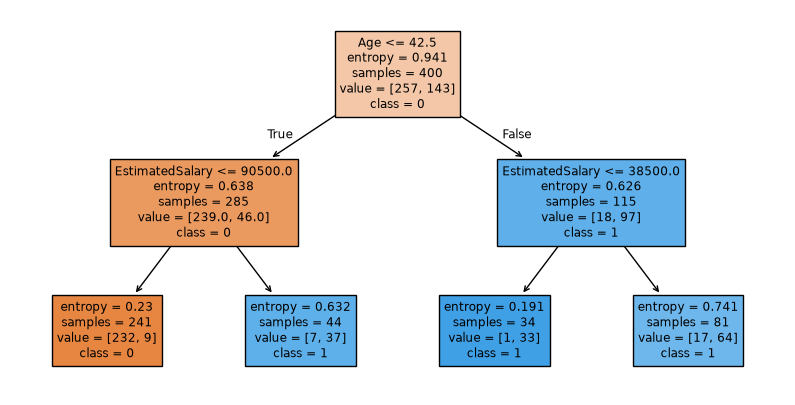

Training accuracy (not CV): 0.915


In [7]:
final = DecisionTreeClassifier(**params).fit(X, y)
print(export_text(final, feature_names=list(X.columns)))
plt.figure(figsize=(10, 5))
plot_tree(final, feature_names=list(X.columns), class_names=['0', '1'], filled=True)
plt.show()
print('Training accuracy (not CV):', round(final.score(X, y), 4))

## 6. Predict new customer

In [8]:
new = pd.read_csv('new_customer.csv')
Xn = new.drop(columns=['User ID'])
Xn['Gender'] = (Xn['Gender'] == 'Male').astype(int)
proba = final.predict_proba(Xn[X.columns])[0]
out = new.assign(**{'prediction(Purchased)': final.predict(Xn[X.columns]),
                    'confidence(0)': proba[0].round(4), 'confidence(1)': proba[1].round(4)})
out

,User ID,Gender,Age,EstimatedSalary,prediction(Purchased),confidence(0),confidence(1)
0,15900001,Female,40,100000,1,0.1591,0.8409


1. User ID is just an identifier with no real relation to buying. A tree could still split on it and learn noise, and it doesn't generalize to new IDs such as 15900001.
2. If the folds, depth, or leaf size also changed, you couldn't tell whether the accuracy difference came from the criterion or from the other change. Keeping everything else fixed makes it a fair comparison.
3. Every depth-2 combination tied at 0.9100 (leaf 1–10 all give the same tree). Ties were broken by lowest std, then the shallowest depth, then the largest leaf size. That picks the simplest, least overfit tree: entropy, max_depth=2, min_samples_leaf=10.
4. CV was only used to choose the settings. Once they're chosen, training on all labeled records gives the model the most data, so the final tree is as good as possible for predicting the new customer.
5. Training accuracy is measured on the same records the tree learned from, so it's optimistic. CV accuracy is measured on held-out folds the model never saw, so it estimates performance on new data.